## Agent discussion panel

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mzarnecki/course_llm_agent_apps_with_langchain_and_langgraph/blob/main/notebooks/en/10_1_Application_discussion_panel_with_supervisor_en.ipynb)

| | |
|---|---|
| 🎯 **What you'll learn** | A four-agent discussion panel: a moderator hands the work to researcher, expert and critic agents. |
| 🔑 **API keys** | `OPENAI_API_KEY`, `TAVILY_API_KEY` |
| 💲 **API cost** | moderate – multi-agent loop with many longer requests |
| ⏱️ **Run time** | ~2 min |

### Installing libraries

In [ ]:
# Install this notebook's direct dependencies.
# Skipped when pip is missing, e.g. in the `uv sync` environment, which already has them (see README).
import importlib.util
if importlib.util.find_spec("pip"):
    %pip install -qU langgraph langgraph-supervisor langchain-tavily langchain-openai python-dotenv
# Google Colab: add OPENAI_API_KEY in the Secrets panel (🔑) and grant this notebook access.
# Uncomment these lines to load it from Colab Secrets into this runtime:
# from google.colab import userdata
# import os
# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
# Locally, put OPENAI_API_KEY=... in a .env file; do not commit the key.
# For Tavily search, also add TAVILY_API_KEY to Colab Secrets or your local .env file.
# from google.colab import userdata
# os.environ["TAVILY_API_KEY"] = userdata.get("TAVILY_API_KEY")

In [2]:
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
from langchain_tavily import TavilySearch

web_search = TavilySearch(max_results=3)
web_search_results = web_search.invoke("Who is the president of Poland?")

print(web_search_results["results"][0]["content"])

Following the 1989 amendments to the constitution which restored the presidency, general Wojciech Jaruzelski, the existing head of state, took office. In Poland's first direct presidential election, Lech Wałęsa won and was sworn in on 22 December 1990. The office of the president was preserved in the Constitution of Poland passed in 1997; the constitution now provides the requirements for, the duties of and the authority of the office. [...] | Prezydent Rzeczypospolitej Polskiej (Polish) |
| Presidential pennant |
| Incumbent Karol Nawrocki since 6 August 2025 |
| Executive branch of the Polish Government |
| Style "Style (form of address)") | Mr. President "President (government title)") (informal) His Excellency (diplomatic) |
| Status | Head of state Commander-in-chief |
| Member of |  National Security Council "National Security Bureau (Poland)")  National Development Council "National Development Council (Poland)") | [...] The president of Poland (Polish: Prezydent Polski ( "Help:

### Helper functions

In [4]:
from langchain_core.messages import convert_to_messages


def pretty_print_messages(chunk):
    """Print the newest message of each agent step streamed with subgraphs=True."""
    namespace, update = chunk
    if not namespace:  # skip parent graph updates, show what happens inside each agent
        return
    print(f"Update from subgraph {namespace[-1].split(':')[0]}:\n")
    for node_name, node_update in update.items():
        if node_update and "messages" in node_update:
            print(f"Node: {node_name}")
            convert_to_messages(node_update["messages"])[-1].pretty_print()
    print("\n")

### Researcher agent

In [5]:
from langgraph.prebuilt import create_react_agent

research_agent = create_react_agent(
    model="openai:gpt-6.1-sol",
    tools=[web_search],
    prompt=(
"You're the Researcher. You have access to fragments from the 'search engine' (RESEARCH).\n"
"Your goal is to provide factual, concise facts and data supporting the topic.\n"
"Refer to the fragments and do not invent. Write concisely and briefly."
"- After you finish your task, respond directly to the moderator\n"
"- Reply using only the results of your work, do not include the text."
    ),
    name="research_agent",
)

/tmp/ipykernel_647401/4167451546.py:3: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  research_agent = create_react_agent(


### Expert agent

In [6]:
expert_agent = create_react_agent(
    model="openai:gpt-6.1-sol",
    tools=[],
    prompt=(
"You're the Expert. From the available facts, propose a practical solution/plan.\n"
"Include steps, requirements, and a minimal set of decisions. Write concretely."
"- After you finish your task, respond directly to the moderator\n"
"- Reply using only the results of your work, do not include the text."
    ),
    name="expert_agent",
)

/tmp/ipykernel_647401/499878320.py:1: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  expert_agent = create_react_agent(


### Agent critic

In [7]:
critic_agent = create_react_agent(
    model="openai:gpt-6.1-sol",
    tools=[],
    prompt=(
"You're the Critic. Your role is to find gaps, risks, and ambiguities in the proposal.\n"
"Ask probing questions and point out missing elements. Be constructive."
"- After you finish your task, respond directly to the moderator\n"
"- Reply using only the results of your work, do not include the text."
    ),
    name="critic_agent",
)

/tmp/ipykernel_647401/1741809124.py:1: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  critic_agent = create_react_agent(


In [8]:
from typing import Annotated
from langchain_core.tools import tool, InjectedToolCallId
from langgraph.prebuilt import InjectedState
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.types import Command


def create_handoff_tool(*, agent_name: str, description: str | None = None):
    name = f"transfer_to_{agent_name}"
    description = description or f"Ask {agent_name} for help."

    @tool(name, description=description)
    def handoff_tool(
        state: Annotated[MessagesState, InjectedState],
        tool_call_id: Annotated[str, InjectedToolCallId],
    ) -> Command:
        tool_message = {
            "role": "tool",
            "content": f"Successfully transferred to {agent_name}",
            "name": name,
            "tool_call_id": tool_call_id,
        }
        return Command(
            goto=agent_name,
            update={**state, "messages": state["messages"] + [tool_message]},
            graph=Command.PARENT,
        )

    return handoff_tool

# Handoffs
assign_to_research_agent = create_handoff_tool(
    agent_name="research_agent",
    description="Assign task to a researcher agent.",
)

assign_to_expert_agent = create_handoff_tool(
    agent_name="expert_agent",
    description="Assign task to a expert agent.",
)

assign_to_critic_agent = create_handoff_tool(
    agent_name="critic_agent",
    description="Assign task to a critic agent.",
)

### Agent moderator

In [9]:
supervisor_agent = create_react_agent(
    model="openai:gpt-6.1-sol",
    tools=[assign_to_research_agent, assign_to_expert_agent, assign_to_critic_agent],
    prompt=(
"You're the Moderator of a discussion in which 3 agents take part: Researcher, Critic and Expert. You decide whether we finish or continue.\n"
"If we continue, provide a SHORT next research query (research_query) for the Researcher, Critic or Expert. If we finish, summarize the discussion and present in a structured and clear way the answer to the question."
"- Researcher. Searches for information and provides facts that form the basis of further discussion\n"
"- Critic. Looks assertively at the conclusions so far and points out weak points and elements to change or improve\n"
"- Expert. Draws conclusions and makes theses. Tries to solve the task based on the information received from the Researcher and Critic\n"
"Assign the work to one agent at a time, do not call agents in parallel.\n"
"Do not take part in the work discussion yourself."
    ),
    name="supervisor",
)

/tmp/ipykernel_647401/4153230676.py:1: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  supervisor_agent = create_react_agent(


### Budowa grafu

In [10]:
from langgraph.graph import END

# Define the multi-agent supervisor graph
supervisor = (
    StateGraph(MessagesState)
    # NOTE: `destinations` is only needed for visualization and doesn't affect runtime behavior
    .add_node(supervisor_agent, destinations=("research_agent", "expert_agent", "critic_agent", END))
    .add_node(research_agent)
    .add_node(expert_agent)
    .add_node(critic_agent)
    .add_edge(START, "supervisor")
    # always return back to the supervisor
    .add_edge("research_agent", "supervisor")
    .add_edge("expert_agent", "supervisor")
    .add_edge("critic_agent", "supervisor")
    .compile()
)

### Display the graph

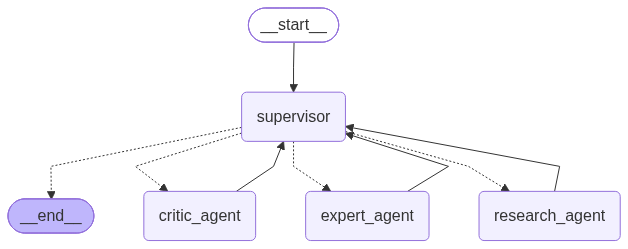

In [11]:
from IPython.display import display, Image

display(Image(supervisor.get_graph().draw_mermaid_png()))

### Conduct a discussion on a given topic and display the answer

In [12]:
RECURSION_LIMIT = 10

for chunk in supervisor.stream(
    {
        "messages": [
            {
                "role": "user",
                "content":" What field is best to study to have a well-paid and interesting profession in 10 years.",
            }
        ]
    },
    subgraphs=True,
    config={"recursion_limit": RECURSION_LIMIT},
):
    pretty_print_messages(chunk)

Update from subgraph supervisor:

Node: agent
================================== Ai Message ==================================
Name: supervisor

[{'type': 'text', 'text': '**Research query for Researcher:** Which fields are likely to offer strong pay and engaging work in 10 years, considering automation, demand, and uncertainty across countries?\n', 'annotations': [], 'id': 'msg_0df2dcb0056bb3ef006ad713dce8e887d2b8ebfcaa128b4c93', 'phase': 'commentary'}, {'arguments': '{}', 'call_id': 'call_HfxoWtHufLkIEmKaloZfzYHw', 'name': 'transfer_to_research_agent', 'type': 'function_call', 'id': 'fc_0df2dcb0056bb3ef006ad713dde5a487d2a19ff2a4ed163bed', 'status': 'completed'}]
Tool Calls:
  transfer_to_research_agent (call_HfxoWtHufLkIEmKaloZfzYHw)
 Call ID: call_HfxoWtHufLkIEmKaloZfzYHw
  Args:




Update from subgraph research_agent:

Node: agent
================================== Ai Message ==================================
Name: research_agent

[{'arguments': '{"query":"site.bls.gov occupational outlook 2024 2034 data scientists information security analysts nurse practitioners software developers median pay","include_domains":["bls.gov"],"exclude_domains":[],"search_depth":"advanced","include_images":false,"time_range":null,"topic":"general","start_date":null,"end_date":null}', 'call_id': 'call_M0UyJXg6HDkcBa4CH1fLMgJU', 'name': 'tavily_search', 'type': 'function_call', 'id': 'fc_0df2dcb0056bb3ef006ad713e298cc87d2b1c3ce4575297838', 'status': 'completed'}, {'arguments': '{"query":"site.weforum.org future jobs report 2025 fastest growing jobs 2030 AI big data renewable energy","include_domains":["weforum.org"],"exclude_domains":[],"search_depth":"basic","include_images":false,"time_range":null,"topic":"general","start_date":null,"end_date":null}', 'call_id': 'call_tJmXescTmKN7

Update from subgraph research_agent:

Node: tools
================================= Tool Message =================================
Name: tavily_search

{"query": "site.weforum.org future jobs report 2025 fastest growing jobs 2030 AI big data renewable energy", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.weforum.org/publications/the-future-of-jobs-report-2025", "title": "The Future of Jobs Report 2025 | World Economic Forum", "content": "Technology-related roles are the fastest- growing jobs in percentage terms, including Big Data Specialists, Fintech Engineers, AI and Machine Learning Specialists and Software and Application Developers. Green and energy transition roles, including Autonomous and Electric Vehicle Specialists, Environmental Engineers, and Renewable Energy Engineers, also feature within the top fastest-growing roles. [...] AI and big data top the list of fastest-growing skills, followed closely by networks and cybersecurity 

Update from subgraph research_agent:

Node: agent
================================== Ai Message ==================================
Name: research_agent

[{'type': 'text', 'text': '**Best-supported choices: computer science with strong mathematics, cybersecurity, and healthcare.** No field guarantees high pay or interesting work in ten years; personal fit and country matter.\n\n| Field to study | Example profession | U.S. median annual pay, 2024 | Projected U.S. employment growth, 2024–34 |\n|---|---|---:|---:|\n| Computer science, statistics, applied mathematics | Data scientist | $112,590 | 33.5% |\n| Computer science or cybersecurity | Information security analyst | $124,910 | 28.5% |\n| Nursing, followed by advanced clinical training | Nurse practitioner | $129,210 | 40.1% |\n\nThese are occupational medians—not starting salaries or predicted future salaries. [Source: U.S. Bureau of Labor Statistics](https://www.bls.gov/opub/mlr/2026/article/industry-and-occupational-employment-proj

Update from subgraph supervisor:

Node: agent
================================== Ai Message ==================================
Name: supervisor

[{'id': 'rs_0df2dcb0056bb3ef006ad713f344d487d2bb1394c9447623f6', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABq1xP1VaK3l8sEon9ixOp29DYeCbr1LcT6jWloUlRxe2QPuWHBdbtQThbpQHTeEHmzonWNnHg-1llElOjX7tuG_1ZRZjdSuX7EKowrgG8MBvPNRSorOdsA_jSAnThEvQhtRk3aTGVFHm4mU9VQ-Ngk75Osx4E-ogLgPml-B1j5bmZuDFCSE36o6nVRU1ytrAR81rUA7kzhWJa59pfMzcXNTbutRESE3zuCukXIqT47Tw-RA0W_tmQ6XQ7V09vuQTyFHKpAVMeD0sicNpzhZDxDZ-noYqOusL5Qmc819UqqrvTYmchuquqGIRDrg-JCxunErfyox7rjvRKCn74xTpvBMHBTQ4LsDyUXR0dpQgMB8hDA9F2BPaUU2G5yUt4hyYj5xOTO-agxndGlLxrA0f8wcbNtdWWQI4fVetjFcnTDesM6ebEf1b4IsI6M8N0j48oKNkV0rVnWqUXNS_Ivpur7TRoRJe5kRuPr0rBJ28Z3M_PV3AEeKn1bWD6HjS1g3-mARTQviwyvSzs8TcTnETSWjKv4zk2hh5M3nX6aNayILCLmxo95IATc7KU83Nudj3bVwwUbMmHDtewc3bCDP8VKb2bPxRU3IalsxWh5WElzSHM1fuA33F7MJCDlbotFASm8F2-d7of6OB8Duf5MxTa9CKEATli873ZDmKvIrVUnt0bNmGcSUtFtsgyQDdYO7-ot2rLCs

Update from subgraph critic_agent:

Node: agent
================================== Ai Message ==================================
Name: critic_agent

Moderator, the shortlist is reasonable, but it needs these qualifications:

- **Do not present a universal “best” field.** Country, academic strengths, preferred working style, and training budget could change the ranking substantially. Ask: *Where do you plan to work, which subjects do you enjoy, and how many years can you spend training?*

- **Separate long-term demand from entry-level accessibility.** Growing employment does not mean easy entry. Cybersecurity roles often require prior IT experience; some AI and research positions require graduate study. Recommend concrete entry pathways, internships, and practical projects—not just degree titles.

- **Treat automation as a task-level risk.** Computer science remains a plausible choice, but routine coding and analysis may increasingly be automated. Strong fundamentals, domain expertise, 

Update from subgraph supervisor:

Node: agent
================================== Ai Message ==================================
Name: supervisor

[{'type': 'text', 'text': '**Research query for Expert:** Give a concise, conditional recommendation and practical study plan, incorporating the Critic’s caveats without promising future salaries.\n', 'annotations': [], 'id': 'msg_0df2dcb0056bb3ef006ad71409642887d2858f29f3906729b1', 'phase': 'commentary'}, {'arguments': '{}', 'call_id': 'call_1AGS2gaiNdgnVF62w0PkVJPs', 'name': 'transfer_to_expert_agent', 'type': 'function_call', 'id': 'fc_0df2dcb0056bb3ef006ad7140a3a4c87d28dc10cb57afd33e1', 'status': 'completed'}]
Tool Calls:
  transfer_to_expert_agent (call_1AGS2gaiNdgnVF62w0PkVJPs)
 Call ID: call_1AGS2gaiNdgnVF62w0PkVJPs
  Args:




Update from subgraph expert_agent:

Node: agent
================================== Ai Message ==================================
Name: expert_agent

Moderator, **my default recommendation is computer science with strong mathematics and statistics—if you enjoy analytical problem-solving.** It offers flexibility across software, AI, data, and cybersecurity. However, no degree guarantees high pay or job security in 2036.

Choose according to the work you actually enjoy:

| If you prefer… | Consider studying… | Main trade-off |
|---|---|---|
| Abstract problems and building digital tools | **Computer science + statistics**, later specializing in AI, data, or cybersecurity | Competitive entry-level hiring; continuous learning required |
| Physical systems, electronics, and machines | **Electrical engineering**, with energy, controls, or robotics electives | Opportunities depend on local industries; some roles require licensing |
| Working directly with people and accepting clinical responsi

Update from subgraph supervisor:

Node: agent
================================== Ai Message ==================================
Name: supervisor

[{'type': 'text', 'text': '**My best general recommendation is computer science with strong mathematics and statistics—if you enjoy analytical problem-solving.** It gives you flexibility across software, AI, data, and cybersecurity rather than tying you to one job title.\n\nBut for a well-paid **and interesting** career around 2036, the best choice depends on what you enjoy doing:\n\n| If you enjoy… | Strong field to study | Main trade-off |\n|---|---|---|\n| Logic, abstract problems, building digital tools | **Computer science + statistics**, then specialize | Competitive entry-level hiring; continual learning |\n| Electronics, machines, understanding how things work | **Electrical engineering**, with energy, robotics, or controls | Opportunities vary by local industry |\n| Biology, helping people, direct responsibility | **Medicine or nursin